In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 500)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [3]:
df = pd.read_csv("datasets/vehicle-dataset/car data.csv")

In [4]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.350,5.590,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.750,9.540,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.250,9.850,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.850,4.150,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.600,6.870,42450,Diesel,Dealer,Manual,0


In [5]:
df.shape

(301, 9)

In [6]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'], dtype='object')

In [7]:
df.dtypes

Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type         object
Seller_Type       object
Transmission      object
Owner              int64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


## Case Nedir?

- Bu datasette linear regression modeli ile araç fiyat tahmini yapmamız bekleniyor.

- Sütun isimleri: Car Name, Year, Selling Price, Present_Price, Kms_Driven, Fuel_Type, Seller_Type, Transmission, Owner

## Regresyon Nedir?

Regresyon, bir veya birden fazla bağımsız değişken arasındaki ilişkiyi kullanarak sürekli bir sayısal değer tahmin etme işlemidir. Binary classification'dan farklı olarak, çıktı kategorik değil, sürekli bir sayısal değerdir

## Preprocessing Functions

In [9]:
def cat_summary(dataframe, col_name, plot=False):
    print(pd.DataFrame({col_name: dataframe[col_name].value_counts(),
                       "Ratio": 100 * dataframe[col_name].value_counts() / len(dataframe)}))
    print("##########################################")
    if plot:
        sns.countplot(x=dataframe[col_name], data=dataframe)
        plt.show()

In [10]:
def check_df(dataframe, head=5):
    print("##################### Shape #####################")
    print(dataframe.shape)
    print("##################### Types #####################")
    print(dataframe.dtypes)
    print("##################### Head #####################")
    print(dataframe.head(head))
    print("##################### Tail #####################")
    print(dataframe.tail(head))
    print("##################### NA #####################")
    print(dataframe.isnull().sum())
    print("##################### Quantiles #####################")
    numeric_columns = dataframe.select_dtypes(include=[np.number]).columns
    print(dataframe[numeric_columns].quantile([0, 0.05, 0.50, 0.95, 0.99, 1]).T)


In [11]:
def num_summary(dataframe, numerical_col, plot=False):
    quantiles = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
    print(dataframe[numerical_col].describe(quantiles).T)

    if plot:
        dataframe[numerical_col].hist(bins=20)
        plt.xlabel(numerical_col)
        plt.title(numerical_col)
        plt.show(block=True)

In [12]:
def outlier_thresholds(dataframe, col_name, q1=0.25, q3=0.75):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit


In [13]:
def check_outlier(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    # Aykırı değerleri boolean mask ile belirle
    outlier_mask = (dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)
    # Herhangi bir True değeri var mı diye kontrol et
    return outlier_mask.any()

In [14]:
def replace_with_thresholds(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    dataframe.loc[(dataframe[col_name] < low_limit), col_name] = low_limit
    dataframe.loc[(dataframe[col_name] > up_limit), col_name] = up_limit


In [15]:
def correlation_matrix(dataframe, cols):
    fig = plt.gcf()
    fig.set_size_inches(10,8)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    fig = sns.heatmap(dataframe[cols].corr(), annot=True, linewidths=0.5, annot_kws={'size': 12}, linecolor='w', cmap='RdBu')
    plt.show(block=True)

In [16]:
def grab_col_names(dataframe, cat_th=10, car_th=20):
    cat_cols = [col for col in dataframe.columns if dataframe[col].dtypes == "O"]
    #numeric olup kategorik olan değişkenler
    num_but_cat = [col for col in dataframe.columns if dataframe[col].nunique() < cat_th and dataframe[col].dtypes != "O"]
    #kategorik olup kardinalitesi yüksek olan değişkenler
    cat_but_car = [col for col in dataframe.columns if dataframe[col].dtypes == "O" and dataframe[col].nunique() > car_th]
    cat_cols += num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]
    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes != "O" and col not in num_but_cat]

    print(f"Observations: {dataframe.shape[0]}")
    print(f"Variables: {dataframe.shape[1]}")
    print(f"cat_cols: {len(cat_cols)}")
    print(f"num_cols: {len(num_cols)}")
    print(f"cat_but_car: {len(cat_but_car)}")
    print(f"num_but_cat: {len(num_but_cat)}")
    
    return cat_cols, num_cols, cat_but_car


In [17]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'], dtype='object')

# Feature Engineering

## Visualization

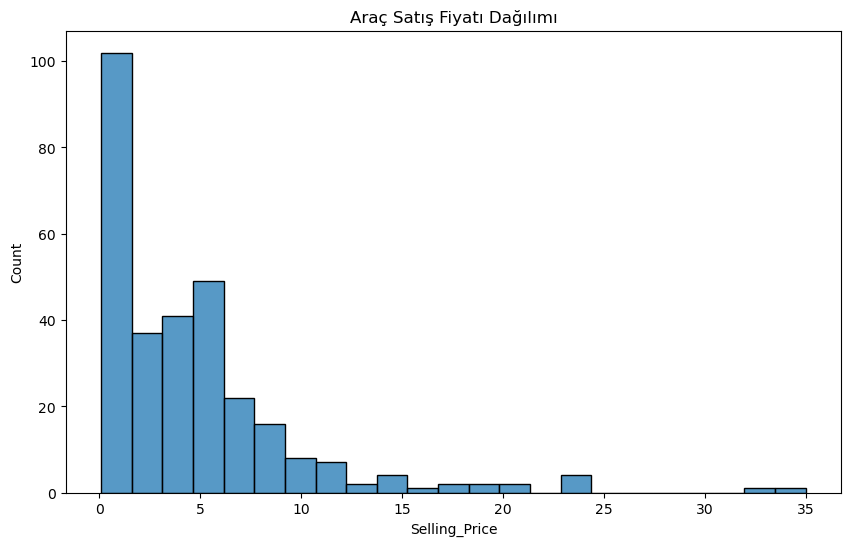

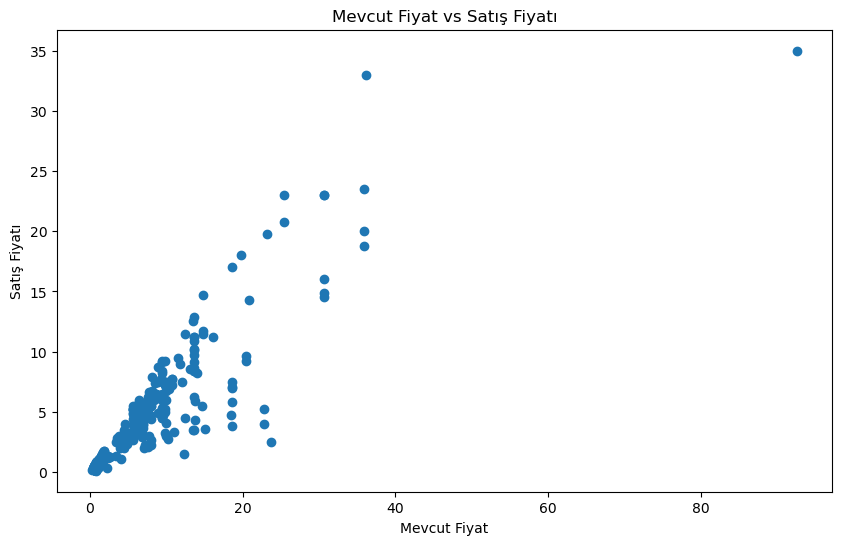

In [18]:
# Satış Fiyatı Dağılımı
plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Selling_Price')
plt.title('Araç Satış Fiyatı Dağılımı')
plt.show()

# Mevcut Fiyat vs Satış Fiyatı Karşılaştırması
plt.figure(figsize=(10,6))
plt.scatter(df['Present_Price'], df['Selling_Price'])
plt.xlabel('Mevcut Fiyat')
plt.ylabel('Satış Fiyatı')
plt.title('Mevcut Fiyat vs Satış Fiyatı')
plt.show()

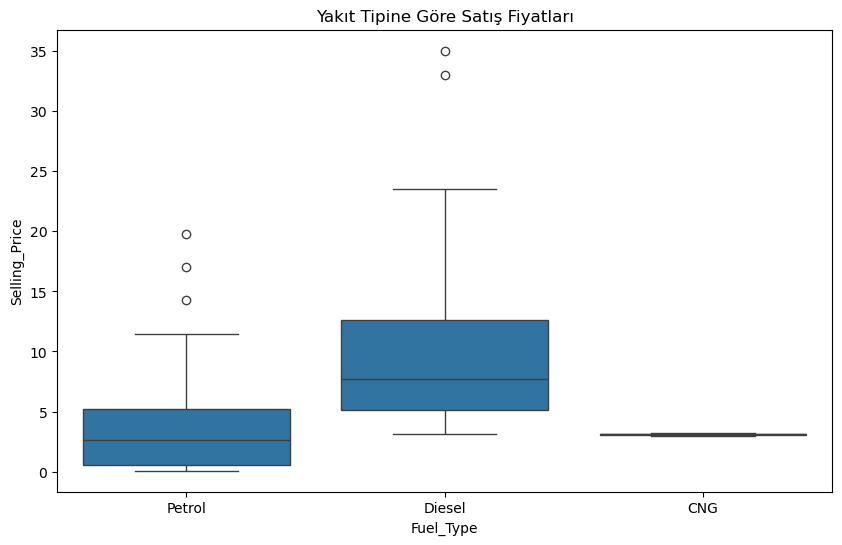

In [19]:
# Yakıt Tipine Göre Ortalama Satış Fiyatı
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Fuel_Type', y='Selling_Price')
plt.title('Yakıt Tipine Göre Satış Fiyatları')
plt.show()

## Dizel araçların satış fiyatının genel olarak benzinli araçlara göre daha yüksek olduğunu gözlemliyoruz.
## Dizel araçların fiyat aralığı daha geniştir

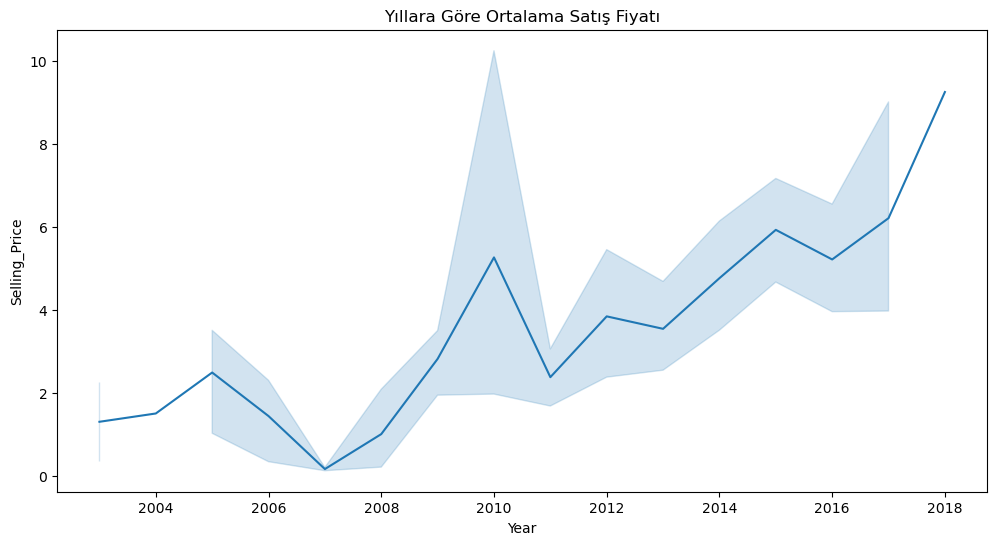

In [20]:
# Yıllara Göre Ortalama Satış Fiyatı
plt.figure(figsize=(12,6))
sns.lineplot(data=df, x='Year', y='Selling_Price')
plt.title('Yıllara Göre Ortalama Satış Fiyatı')
plt.show()

## Genel olarak artan bir trend gözlemliyoruz
## Özellikle 2008 den sonra belirgin bir yükseliş trendi başladığını görüyoruz
## 2018 e doğru fiyatlardaki artışın hızlandığını gözlemliyoruz
## 2010-2011 döneminde yüksek fiyat değişkenliği gözlemleniyor


## Üretim yılı, fiyat tahmininde önemli bir değişken olarak kullanılabilir
## Daha yeni araçların daha yüksek fiyatlara sahip olma eğilimi vardır


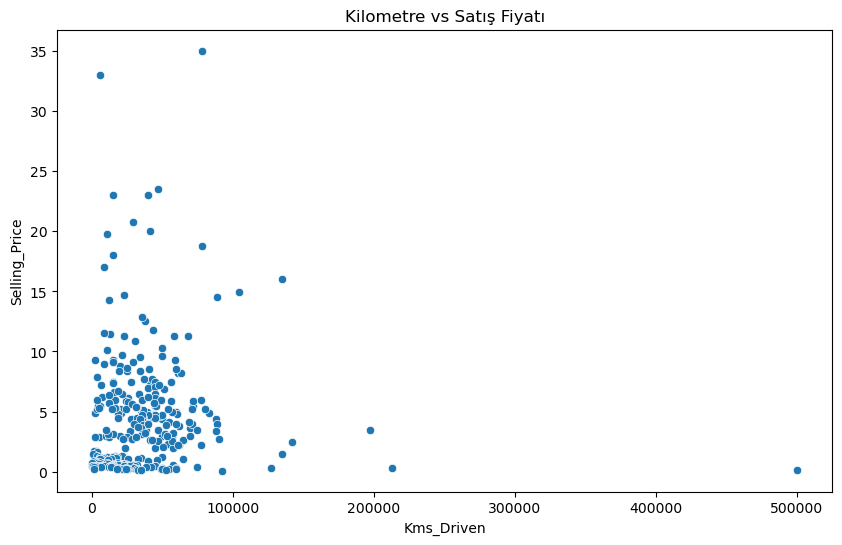

In [21]:
# Kilometre vs Satış Fiyatı İlişkisi
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Kms_Driven', y='Selling_Price')
plt.title('Kilometre vs Satış Fiyatı')
plt.show()


## Kilometre arttıkça satış fiyatının azaldığını gözlemliyoruz
## Düşük kilometreli araçlarda fiyat aralığı daha geniştir


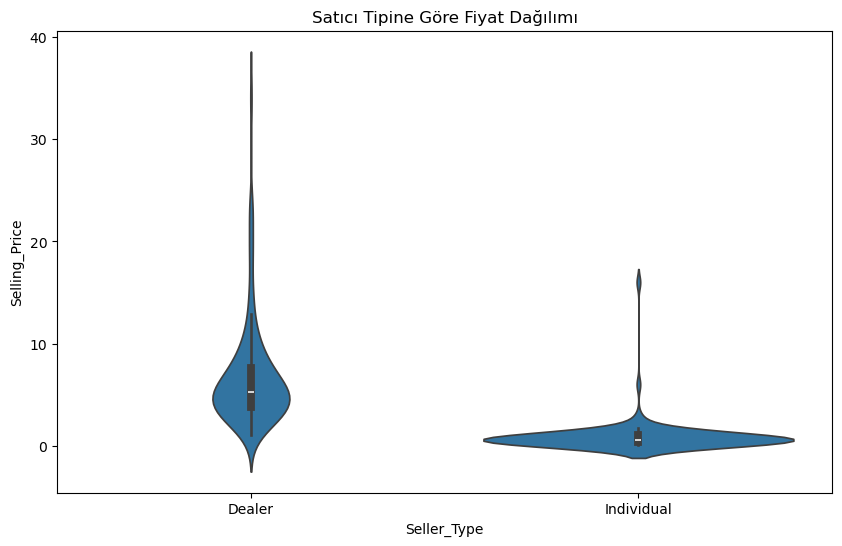

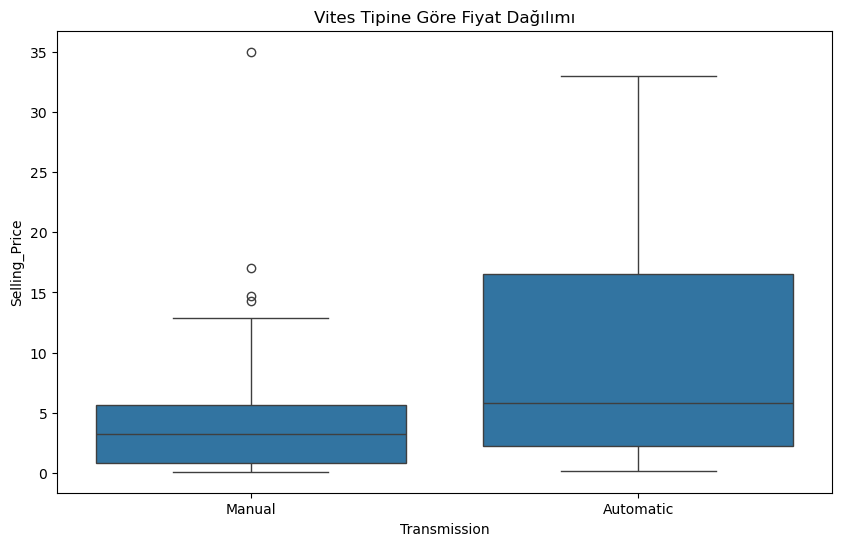

In [22]:
# Satıcı Tipine Göre Fiyat Dağılımı
plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='Seller_Type', y='Selling_Price')
plt.title('Satıcı Tipine Göre Fiyat Dağılımı')
plt.show()

# Vites Tipine Göre Fiyat Dağılımı
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Transmission', y='Selling_Price')
plt.title('Vites Tipine Göre Fiyat Dağılımı')
plt.show()


## Dealer (bayi) satışlarının fiyat dağılımı individual (bireysel) satışlara göre daha geniş
## bir aralığa sahip olduğunu gözlemliyoruz
## Dealer ların ortalama satış fiyatı bireysel satışlara göre daha yüksektir


## Genel olarak otomatik vitesli araçların fiyatları daha yüksek ve fiyat aralığı daha geniştir


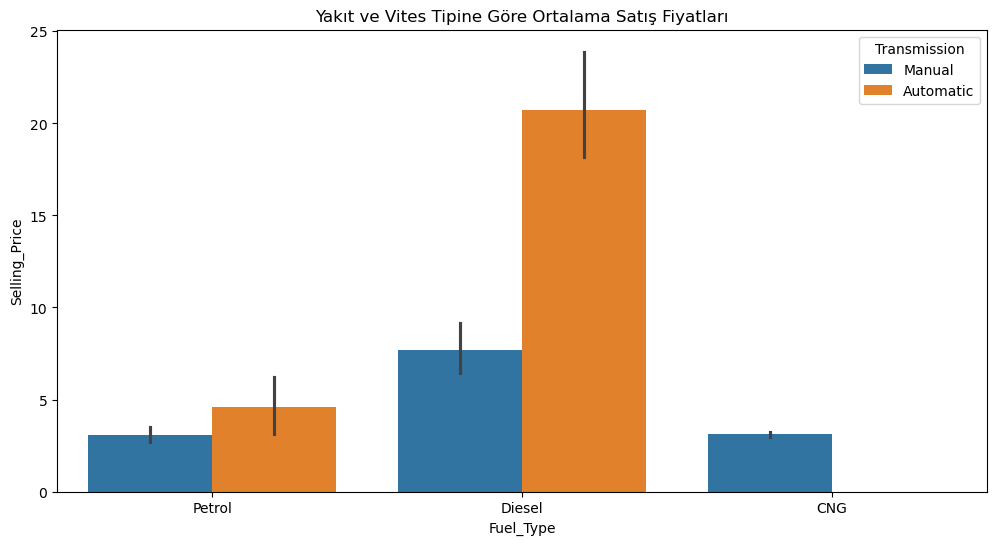

In [23]:
# Yakıt Tipi ve Vites Tipine Göre Ortalama Fiyatlar
plt.figure(figsize=(12,6))
sns.barplot(data=df, x='Fuel_Type', y='Selling_Price', hue='Transmission')
plt.title('Yakıt ve Vites Tipine Göre Ortalama Satış Fiyatları')
plt.show()


## Dizel araçlarda otomatik vitesli araçlar ile manuel vitesli araçlar arasında
## büyük bir fiyat farkı gözlemleniyor

## Benzinli araçlarda ise bu fark daha azdır


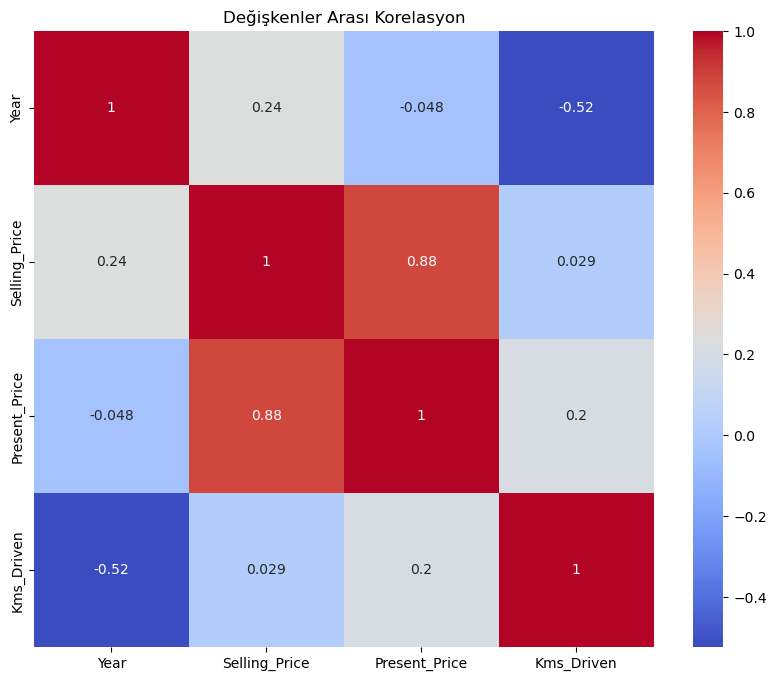

In [24]:
# Sayısal değişkenler arası korelasyon
numeric_cols = ['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven']
plt.figure(figsize=(10,8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm')
plt.title('Değişkenler Arası Korelasyon')
plt.show()


## Sellin Price ile Present Price arasında çok güçlü pozitif korelasyon gözlemliyoruz
## Year ile zayıf bir korelasyon gözlemleniyor
## Kms_Driven ile de zayıf negatif korelasyon gözlemleniyor, neredeyse ilişkisiz


### Feature Extraction

In [25]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'], dtype='object')

In [26]:
df["Seller_Type"].value_counts()

Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64

In [27]:
df["Owner"].value_counts()

Owner
0    290
1     10
3      1
Name: count, dtype: int64

In [28]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'], dtype='object')

In [29]:
from datetime import datetime


In [30]:
current_year = datetime.now().year


In [31]:
df["Vehicle_Age"] = current_year - df["Year"]


In [32]:
df["Vehicle_Age"].head()


0    11
1    12
2     8
3    14
4    11
Name: Vehicle_Age, dtype: int64

In [33]:
df["Price_Difference"] = df["Present_Price"] - df["Selling_Price"]

In [34]:
df["Price_Difference"].head()

0   2.240
1   4.790
2   2.600
3   1.300
4   2.270
Name: Price_Difference, dtype: float64

In [35]:
df["Kms_Driven"].describe()


count      301.000
mean     36947.206
std      38886.884
min        500.000
25%      15000.000
50%      32000.000
75%      48767.000
max     500000.000
Name: Kms_Driven, dtype: float64

In [36]:
df["Kms_Driven"].head()


0    27000
1    43000
2     6900
3     5200
4    42450
Name: Kms_Driven, dtype: int64

In [37]:
df['Km_Category'] = pd.cut(df['Kms_Driven'], bins=[0, 20000, 50000, 100000, float('inf')], labels=['Low', 'Medium', 'High', 'Very High'])

In [38]:
df["Km_Category"].value_counts()


Km_Category
Medium       134
Low          101
High          58
Very High      8
Name: count, dtype: int64

In [39]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Vehicle_Age,Price_Difference,Km_Category
0,ritz,2014,3.350,5.590,27000,Petrol,Dealer,Manual,0,11,2.240,Medium
1,sx4,2013,4.750,9.540,43000,Diesel,Dealer,Manual,0,12,4.790,Medium
2,ciaz,2017,7.250,9.850,6900,Petrol,Dealer,Manual,0,8,2.600,Low
3,wagon r,2011,2.850,4.150,5200,Petrol,Dealer,Manual,0,14,1.300,Low
4,swift,2014,4.600,6.870,42450,Diesel,Dealer,Manual,0,11,2.270,Medium


In [40]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Vehicle_Age', 'Price_Difference', 'Km_Category'], dtype='object')

In [41]:
df["Car_Name"].head()

0       ritz
1        sx4
2       ciaz
3    wagon r
4      swift
Name: Car_Name, dtype: object

In [42]:
df.tail()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Vehicle_Age,Price_Difference,Km_Category
296,city,2016,9.500,11.600,33988,Diesel,Dealer,Manual,0,9,2.100,Medium
297,brio,2015,4.000,5.900,60000,Petrol,Dealer,Manual,0,10,1.900,High
298,city,2009,3.350,11.000,87934,Petrol,Dealer,Manual,0,16,7.650,High
299,city,2017,11.500,12.500,9000,Diesel,Dealer,Manual,0,8,1.000,Low
300,brio,2016,5.300,5.900,5464,Petrol,Dealer,Manual,0,9,0.600,Low


In [43]:
df.Car_Name.value_counts()


Car_Name
city                         26
corolla altis                16
verna                        14
fortuner                     11
brio                         10
ciaz                          9
innova                        9
i20                           9
grand i10                     8
jazz                          7
amaze                         7
Royal Enfield Classic 350     7
ertiga                        6
eon                           6
sx4                           6
alto k10                      5
i10                           5
swift                         5
Bajaj Pulsar 150              4
Royal Enfield Thunder 350     4
ritz                          4
wagon r                       4
etios liva                    4
dzire                         4
xcent                         3
etios cross                   3
Royal Enfield Thunder 500     3
TVS Apache RTR 160            3
Yamaha FZ S V 2.0             3
creta                         3
Honda CB Hornet 160R          3

In [44]:
df["Km_Per_Year"] = df["Kms_Driven"] / df["Vehicle_Age"]

In [45]:
df['Price_Per_Km'] = df['Selling_Price'] / df['Kms_Driven']

In [46]:
cat_cols, num_cols, cat_but_car = grab_col_names(df, cat_th=10, car_th=20)

Observations: 301
Variables: 14
cat_cols: 5
num_cols: 8
cat_but_car: 1
num_but_cat: 2


In [47]:
cat_cols

['Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Km_Category']

In [48]:
df.Owner.value_counts()


Owner
0    290
1     10
3      1
Name: count, dtype: int64

In [49]:
num_cols

['Year',
 'Selling_Price',
 'Present_Price',
 'Kms_Driven',
 'Vehicle_Age',
 'Price_Difference',
 'Km_Per_Year',
 'Price_Per_Km']

In [50]:
cat_but_car

['Car_Name']

## Outliers

In [51]:
for col in num_cols:
    print(col, check_outlier(df, col))


Year True
Selling_Price True
Present_Price True
Kms_Driven True
Vehicle_Age True
Price_Difference True
Km_Per_Year True
Price_Per_Km True


In [52]:
for col in num_cols:
   replace_with_thresholds(df, col)

In [53]:
for col in num_cols:
    print(col, check_outlier(df, col))

Year False
Selling_Price False
Present_Price False
Kms_Driven False
Vehicle_Age False
Price_Difference False
Km_Per_Year False
Price_Per_Km False


In [54]:
def missing_values_table(dataframe, na_name=False):
    na_columns = [col for col in dataframe.columns if dataframe[col].isnull().sum() > 0]

    n_miss = dataframe[na_columns].isnull().sum().sort_values(ascending=False)
    ratio = (dataframe[na_columns].isnull().sum() / dataframe.shape[0] * 100).sort_values(ascending=False)
    missing_df = pd.concat([n_miss, np.round(ratio, 2)], axis=1, keys=['n_miss', 'ratio'])
    print(missing_df, end="\n")

    if na_name:
        return na_columns

In [55]:
missing_values_table(df)

Empty DataFrame
Columns: [n_miss, ratio]
Index: []


In [56]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Vehicle_Age', 'Price_Difference', 'Km_Category', 'Km_Per_Year', 'Price_Per_Km'], dtype='object')

## Label Encoding

In [57]:
binary_cols = [col for col in df.columns if df[col].dtype not in [int, float] and df[col].nunique() == 2]

In [58]:
binary_cols

['Seller_Type', 'Transmission']

In [59]:
from sklearn.preprocessing import LabelEncoder

In [60]:
def label_encoder(dataframe, binary_col):
    labelencoder = LabelEncoder()
    dataframe[binary_col] = labelencoder.fit_transform(dataframe[binary_col])
    return dataframe

In [61]:
for col in binary_cols:
    df = label_encoder(df, col)

## Rare Encoding

In [62]:
def rare_analyser(dataframe, target, cat_cols):
    for col in cat_cols:
        print(col, ":", len(dataframe[col].value_counts()))
        print(pd.DataFrame({"COUNT": dataframe[col].value_counts(),
                            "RATIO": dataframe[col].value_counts() / len(dataframe),
                            "TARGET_MEAN": dataframe.groupby(col)[target].mean()}), end="\n\n\n")

In [63]:
rare_analyser(df, "Selling_Price", cat_cols)

Fuel_Type : 3
           COUNT  RATIO  TARGET_MEAN
Fuel_Type                           
CNG            2  0.007        3.100
Diesel        60  0.199        8.495
Petrol       239  0.794        3.222


Seller_Type : 2
             COUNT  RATIO  TARGET_MEAN
Seller_Type                           
0              195  0.648        6.133
1              106  0.352        0.849


Transmission : 2
              COUNT  RATIO  TARGET_MEAN
Transmission                           
0                40  0.133        7.153
1               261  0.867        3.831


Owner : 3
       COUNT  RATIO  TARGET_MEAN
Owner                           
0        290  0.963        4.358
1         10  0.033        1.970
3          1  0.003        2.500


Km_Category : 4
             COUNT  RATIO  TARGET_MEAN
Km_Category                           
Low            101  0.336        3.646
Medium         134  0.445        4.580
High            58  0.193        4.626
Very High        8  0.027        4.452




In [64]:
def rare_encoder(dataframe, rare_perc):
    temp_df = dataframe.copy()

    rare_columns = [col for col in temp_df.columns if temp_df[col].dtypes == 'O'
                    and (temp_df[col].value_counts() / len(temp_df) < rare_perc).any(axis=None)]

    for var in rare_columns:
        tmp = temp_df[var].value_counts() / len(temp_df)
        rare_labels = tmp[tmp < rare_perc].index
        temp_df[var] = np.where(temp_df[var].isin(rare_labels), 'Rare', temp_df[var])

    return temp_df

In [65]:
df = rare_encoder(df, 0.01)


## One-Hot Encoding

In [66]:
ohe_cols = [col for col in df.columns if 10 > df[col].nunique() > 2]

In [67]:
ohe_cols

['Fuel_Type', 'Owner', 'Km_Category']

In [68]:
def one_hot_encoder(dataframe, categorical_cols, drop_first=True):
    dataframe = pd.get_dummies(dataframe, columns=categorical_cols, drop_first=drop_first)
    return dataframe

In [69]:
df = one_hot_encoder(df, ohe_cols)

In [70]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Seller_Type,Transmission,Vehicle_Age,Price_Difference,Km_Per_Year,Price_Per_Km,Fuel_Type_Petrol,Fuel_Type_Rare,Owner_1,Owner_3,Km_Category_Medium,Km_Category_High,Km_Category_Very High
0,ritz,2014,3.350,5.590,27000.000,0,1,11,2.240,2454.545,0.000,True,False,False,False,True,False,False
1,sx4,2013,4.750,9.540,43000.000,0,1,12,4.790,3583.333,0.000,False,False,False,False,True,False,False
2,ciaz,2017,7.250,9.850,6900.000,0,1,8,2.600,862.500,0.001,True,False,False,False,False,False,False
3,wagon r,2011,2.850,4.150,5200.000,0,1,14,1.300,371.429,0.001,True,False,False,False,False,False,False
4,swift,2014,4.600,6.870,42450.000,0,1,11,2.270,3859.091,0.000,False,False,False,False,True,False,False


In [71]:
cat_cols, num_cols, cat_but_car = grab_col_names(df)

Observations: 301
Variables: 18
cat_cols: 9
num_cols: 8
cat_but_car: 1
num_but_cat: 9


In [72]:
num_cols

['Year',
 'Selling_Price',
 'Present_Price',
 'Kms_Driven',
 'Vehicle_Age',
 'Price_Difference',
 'Km_Per_Year',
 'Price_Per_Km']

## Feature Selection

In [73]:
useless_cols = [col for col in df.columns if df[col].nunique() == 2 and (df[col].value_counts() / len(df) < 0.01).any(axis=None)]

In [74]:
useless_cols

['Fuel_Type_Rare', 'Owner_3']

In [75]:
df.drop(columns=useless_cols, inplace=True)

In [76]:
from sklearn.preprocessing import StandardScaler


## Standart Scaler

In [77]:
scaler = StandardScaler()

In [78]:
df[num_cols] = scaler.fit_transform(df[num_cols])

In [79]:
df[num_cols].head()

,Year,Selling_Price,Present_Price,Kms_Driven,Vehicle_Age,Price_Difference,Km_Per_Year,Price_Per_Km
0,0.120,-0.246,-0.242,-0.314,-0.120,-0.055,-0.266,-0.294
1,-0.242,0.128,0.400,0.362,0.242,1.013,0.376,-0.374
2,1.206,0.795,0.451,-1.162,-1.206,0.096,-1.171,2.086
3,-0.965,-0.380,-0.476,-1.234,0.965,-0.449,-1.450,2.086
4,0.120,0.088,-0.034,0.339,-0.120,-0.043,0.533,-0.386


## Model

In [80]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Seller_Type', 'Transmission', 'Vehicle_Age', 'Price_Difference', 'Km_Per_Year', 'Price_Per_Km', 'Fuel_Type_Petrol', 'Owner_1', 'Km_Category_Medium', 'Km_Category_High', 'Km_Category_Very High'], dtype='object')

In [81]:
df = pd.get_dummies(df, columns=['Car_Name'])

In [82]:
y = df["Selling_Price"]
X = df.drop(columns=["Selling_Price"], axis=1)

In [83]:
from sklearn.model_selection import train_test_split


In [84]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=17)

In [85]:
from sklearn.linear_model import LinearRegression

In [86]:
# Fit the Linear Regression model
linear_reg = LinearRegression()
linear_reg.fit(X_train, y_train)

LinearRegression()

In [87]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

In [88]:
# Train seti üzerindeki tahminler
y_pred_train = linear_reg.predict(X_train)

# Test seti üzerindeki tahminler
y_pred_test = linear_reg.predict(X_test)

In [89]:
train_r2 = r2_score(y_train, y_pred_train)
train_mae = mean_absolute_error(y_train, y_pred_train)
train_mse = mean_squared_error(y_train, y_pred_train)
train_rmse = np.sqrt(train_mse)

test_r2 = r2_score(y_test, y_pred_test)
test_mae = mean_absolute_error(y_test, y_pred_test)
test_mse = mean_squared_error(y_test, y_pred_test)
test_rmse = np.sqrt(test_mse)

In [90]:
print("Train Seti Performans Metrikleri:")
print("--------------------------------")
print(f"R2 Score: {train_r2:.4f}")
print(f"MAE: {train_mae:.4f}")
print(f"MSE: {train_mse:.4f}")
print(f"RMSE: {train_rmse:.4f}")
print("\nTest Seti Performans Metrikleri:")
print("--------------------------------")
print(f"R2 Score: {test_r2:.4f}")
print(f"MAE: {test_mae:.4f}")
print(f"MSE: {test_mse:.4f}")
print(f"RMSE: {test_rmse:.4f}")

Train Seti Performans Metrikleri:
--------------------------------
R2 Score: 0.9650
MAE: 0.1136
MSE: 0.0364
RMSE: 0.1909

Test Seti Performans Metrikleri:
--------------------------------
R2 Score: 0.9090
MAE: 0.1487
MSE: 0.0792
RMSE: 0.2815


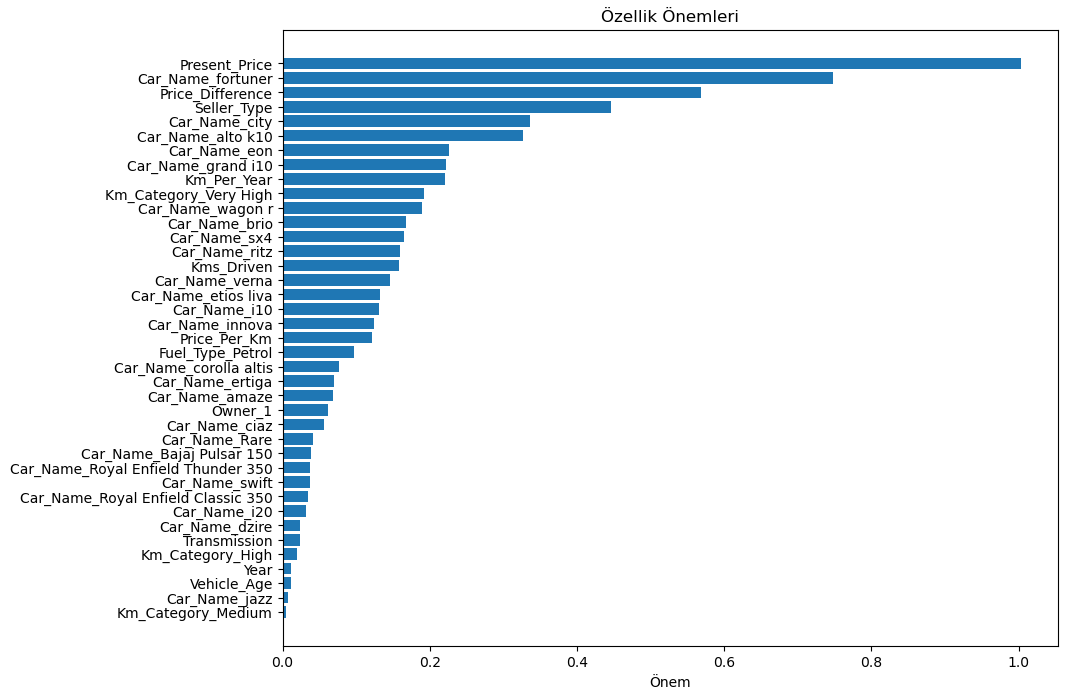

In [91]:
feature_names = X.columns

# Katsayıları al
coefficients = linear_reg.coef_

# Özellik önemini bir DataFrame'e koy
feature_importance = pd.DataFrame({'Feature': feature_names, 'Importance': coefficients})

# Mutlak değerine göre sırala
feature_importance['Importance'] = np.abs(feature_importance['Importance'])
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

# Görselleştir
plt.figure(figsize=(10, 8))
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.xlabel('Önem')
plt.title('Özellik Önemleri')
plt.gca().invert_yaxis()
plt.show()

In [92]:
import autosklearn.regression
import warnings
warnings.filterwarnings('ignore')

In [98]:
bool_columns = X.select_dtypes(include=['bool']).columns
X[bool_columns] = X[bool_columns].astype(int)

# Tüm verileri float64'e çevir
X = X.astype('float64')

In [100]:
# Auto-Sklearn regresyon modelini oluştur
automl = autosklearn.regression.AutoSklearnRegressor(
    time_left_for_this_task=300,  # toplam süre (saniye)
    per_run_time_limit=30,        # her deneme için süre limiti
    ensemble_size=1,              # ensemble boyutu
    metric=autosklearn.metrics.mean_squared_error,
    memory_limit=None,            # RAM limiti
    resampling_strategy='cv',
    resampling_strategy_arguments={'folds': 5}
)

In [101]:
# Train ve test setlerini float64'e çevir
X_train = X_train.astype('float64')
X_test = X_test.astype('float64')
y_train = y_train.astype('float64')
y_test = y_test.astype('float64')

In [102]:
# Modeli eğit
try:
    automl.fit(X_train, y_train)
    
    # Tahminler
    y_pred_train_auto = automl.predict(X_train)
    y_pred_test_auto = automl.predict(X_test)
    
    # Performans metrikleri
    print("Auto-Sklearn Train Seti Performans Metrikleri:")
    print("--------------------------------")
    print(f"R2 Score: {r2_score(y_train, y_pred_train_auto):.4f}")
    print(f"MAE: {mean_absolute_error(y_train, y_pred_train_auto):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train_auto)):.4f}")
    
    print("\nAuto-Sklearn Test Seti Performans Metrikleri:")
    print("--------------------------------")
    print(f"R2 Score: {r2_score(y_test, y_pred_test_auto):.4f}")
    print(f"MAE: {mean_absolute_error(y_test, y_pred_test_auto):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test_auto)):.4f}")
    
    # Model detayları
    print("\nModel İstatistikleri:")
    print(automl.sprint_statistics())
    
    # En iyi modeli göster
    print("\nEn İyi Model:")
    print(automl.leaderboard())
    
except Exception as e:
    print(f"Bir hata oluştu: {str(e)}")

Auto-Sklearn Train Seti Performans Metrikleri:
--------------------------------
R2 Score: 0.9976
MAE: 0.0244
RMSE: 0.0505

Auto-Sklearn Test Seti Performans Metrikleri:
--------------------------------
R2 Score: 0.9463
MAE: 0.0537
RMSE: 0.2161

Model İstatistikleri:
auto-sklearn results:
  Dataset name: c155a98b-df49-11ef-85e0-fc349702228d
  Metric: mean_squared_error
  Best validation score: 0.021726
  Number of target algorithm runs: 20
  Number of successful target algorithm runs: 13
  Number of crashed target algorithm runs: 0
  Number of target algorithms that exceeded the time limit: 7
  Number of target algorithms that exceeded the memory limit: 0


En İyi Model:
          rank  ensemble_weight              type  cost  duration
model_id                                                         
9            1            1.000  gaussian_process 0.022     7.557
